# PieceSpice Curve Extraction — Notebook 01

Vendor-parameterised extraction via `pipeline.curves.run_all_curves`.

Each section below shows one datasheet curve with its extracted values.

In [58]:
# PieceSpice Curve Extraction (M11 + per-curve sections)
import sys, os
from pathlib import Path
REPO_ROOT = Path.cwd()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)   # YAML library paths are repo-root-relative

VENDOR = "cpm2-1200"   # any config/inputs/<name>.yaml stem

import numpy as np
from config.yaml_io import load_input, load_output
from pipeline.curves import run_all_curves
from common.plotting import setup_style
import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter
setup_style()

outputs = run_all_curves(VENDOR)
cfg = load_input(VENDOR)
print(f"Extracted {len(outputs)} curves for {VENDOR}")

[pipeline] cpm2-1200: all 7 curves extracted -> config/outputs/cpm2-1200/
Extracted 7 curves for cpm2-1200


In [59]:
def plot_curve(tb_name, x_key, y_key, title=None, xlabel=None, ylabel=None,
               family_curves=False):
    """Load one saved output YAML and plot the requested keys.

    family_curves=True: plots the Curve-1 style family keyed
    'curve_id_vgs_<v>_v' with a legend per gate drive.
    """
    data = load_output(VENDOR, tb_name)
    ex = data["extracted"]
    fig, ax = plt.subplots(figsize=(10.5, 5.8), layout="constrained")
    if family_curves:
        vgs_keys = [k for k in ex if k.startswith("curve_id_vgs_")]
        vals = sorted(
            float(k.replace("curve_id_vgs_", "").replace("_v", ""))
            for k in vgs_keys)
        cmap = plt.cm.viridis(np.linspace(0, 0.9, max(len(vals), 1)))
        for col, v in zip(cmap, vals):
            k = f"curve_id_vgs_{int(v)}_v"
            ax.plot(ex[k], label=f"Vgs = {v:g} V", color=col)
        ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5),
                  title="Family")
    else:
        ax.plot(ex[x_key], ex[y_key])
    ax.set_title(title or tb_name)
    ax.set_xlabel(xlabel or x_key)
    ax.set_ylabel(ylabel or y_key)
    ax.grid(True, alpha=0.35, ls="--")
    plt.show()
    return data

---
## Curve 1 — Output Characteristics
Id vs Vds family at multiple gate drives.

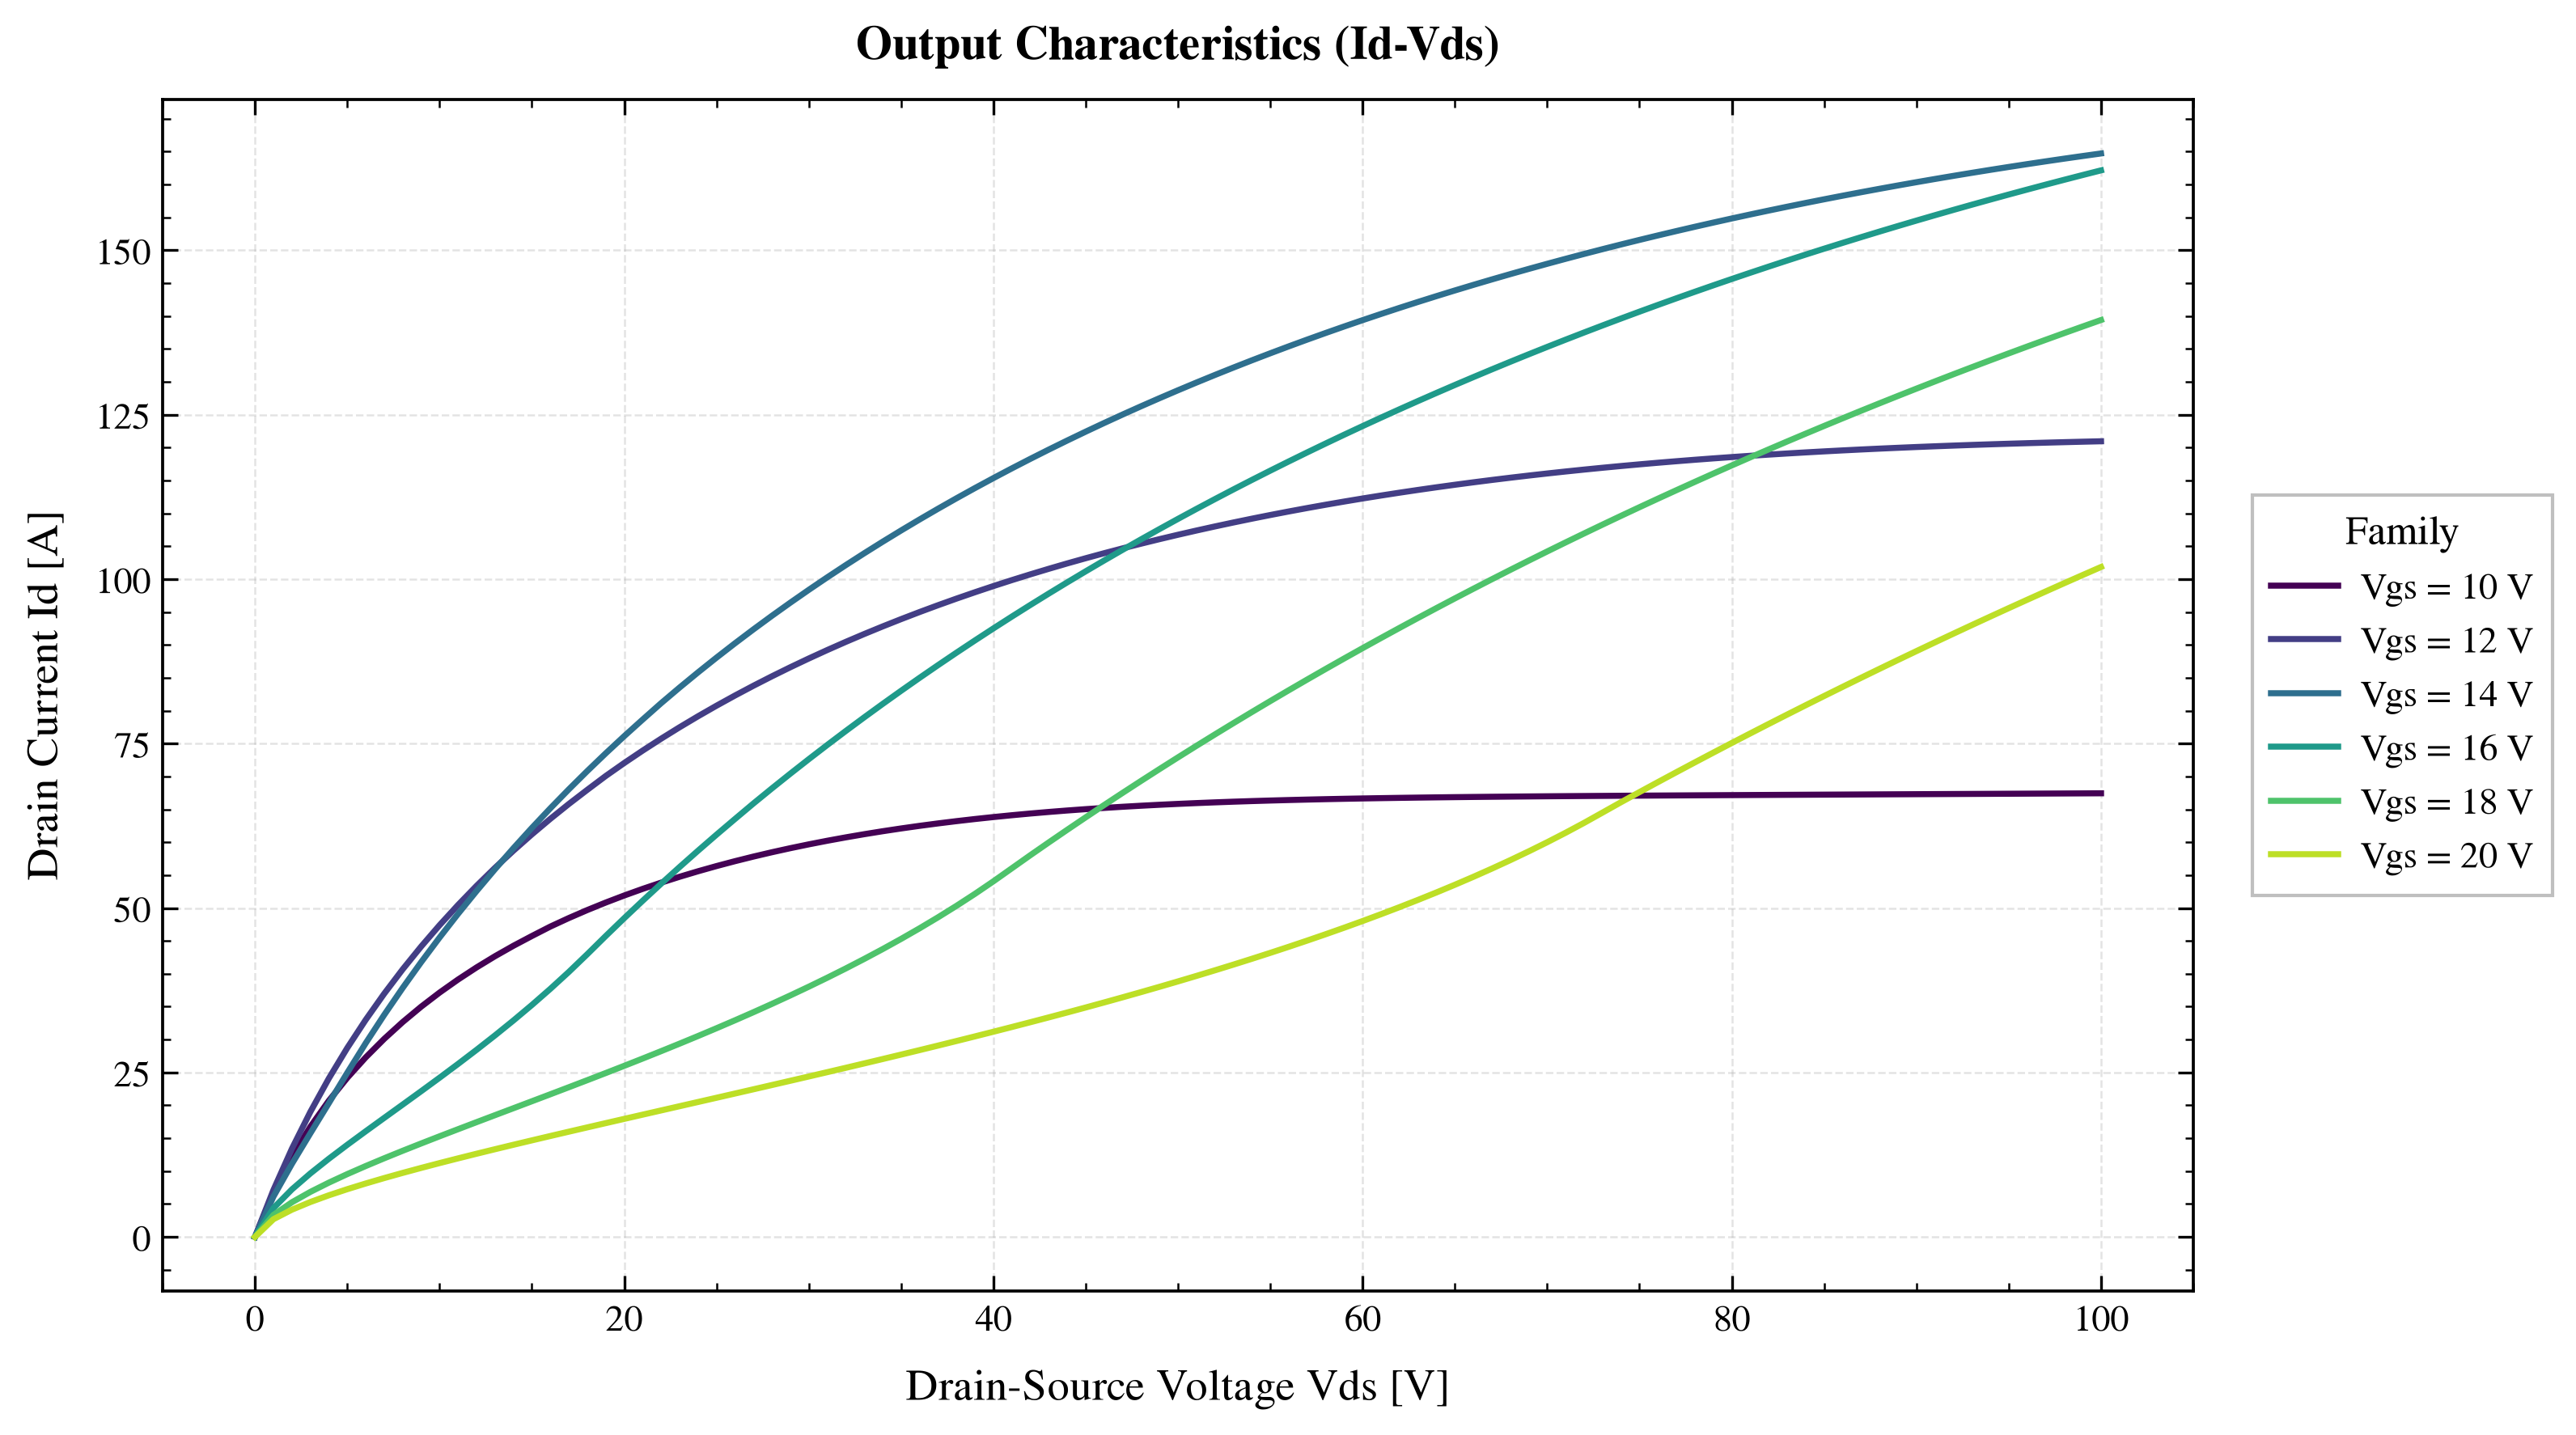

In [60]:
data1 = plot_curve(
    "curve1_output_characteristics", None, None,
    title="Output Characteristics (Id-Vds)",
    xlabel="Drain-Source Voltage Vds [V]",
    ylabel="Drain Current Id [A]",
    family_curves=True)

---
## Curve 2 — Transfer Characteristic
Id vs Vgs at fixed Vds; transconductance gfs evaluated at the load plateau.

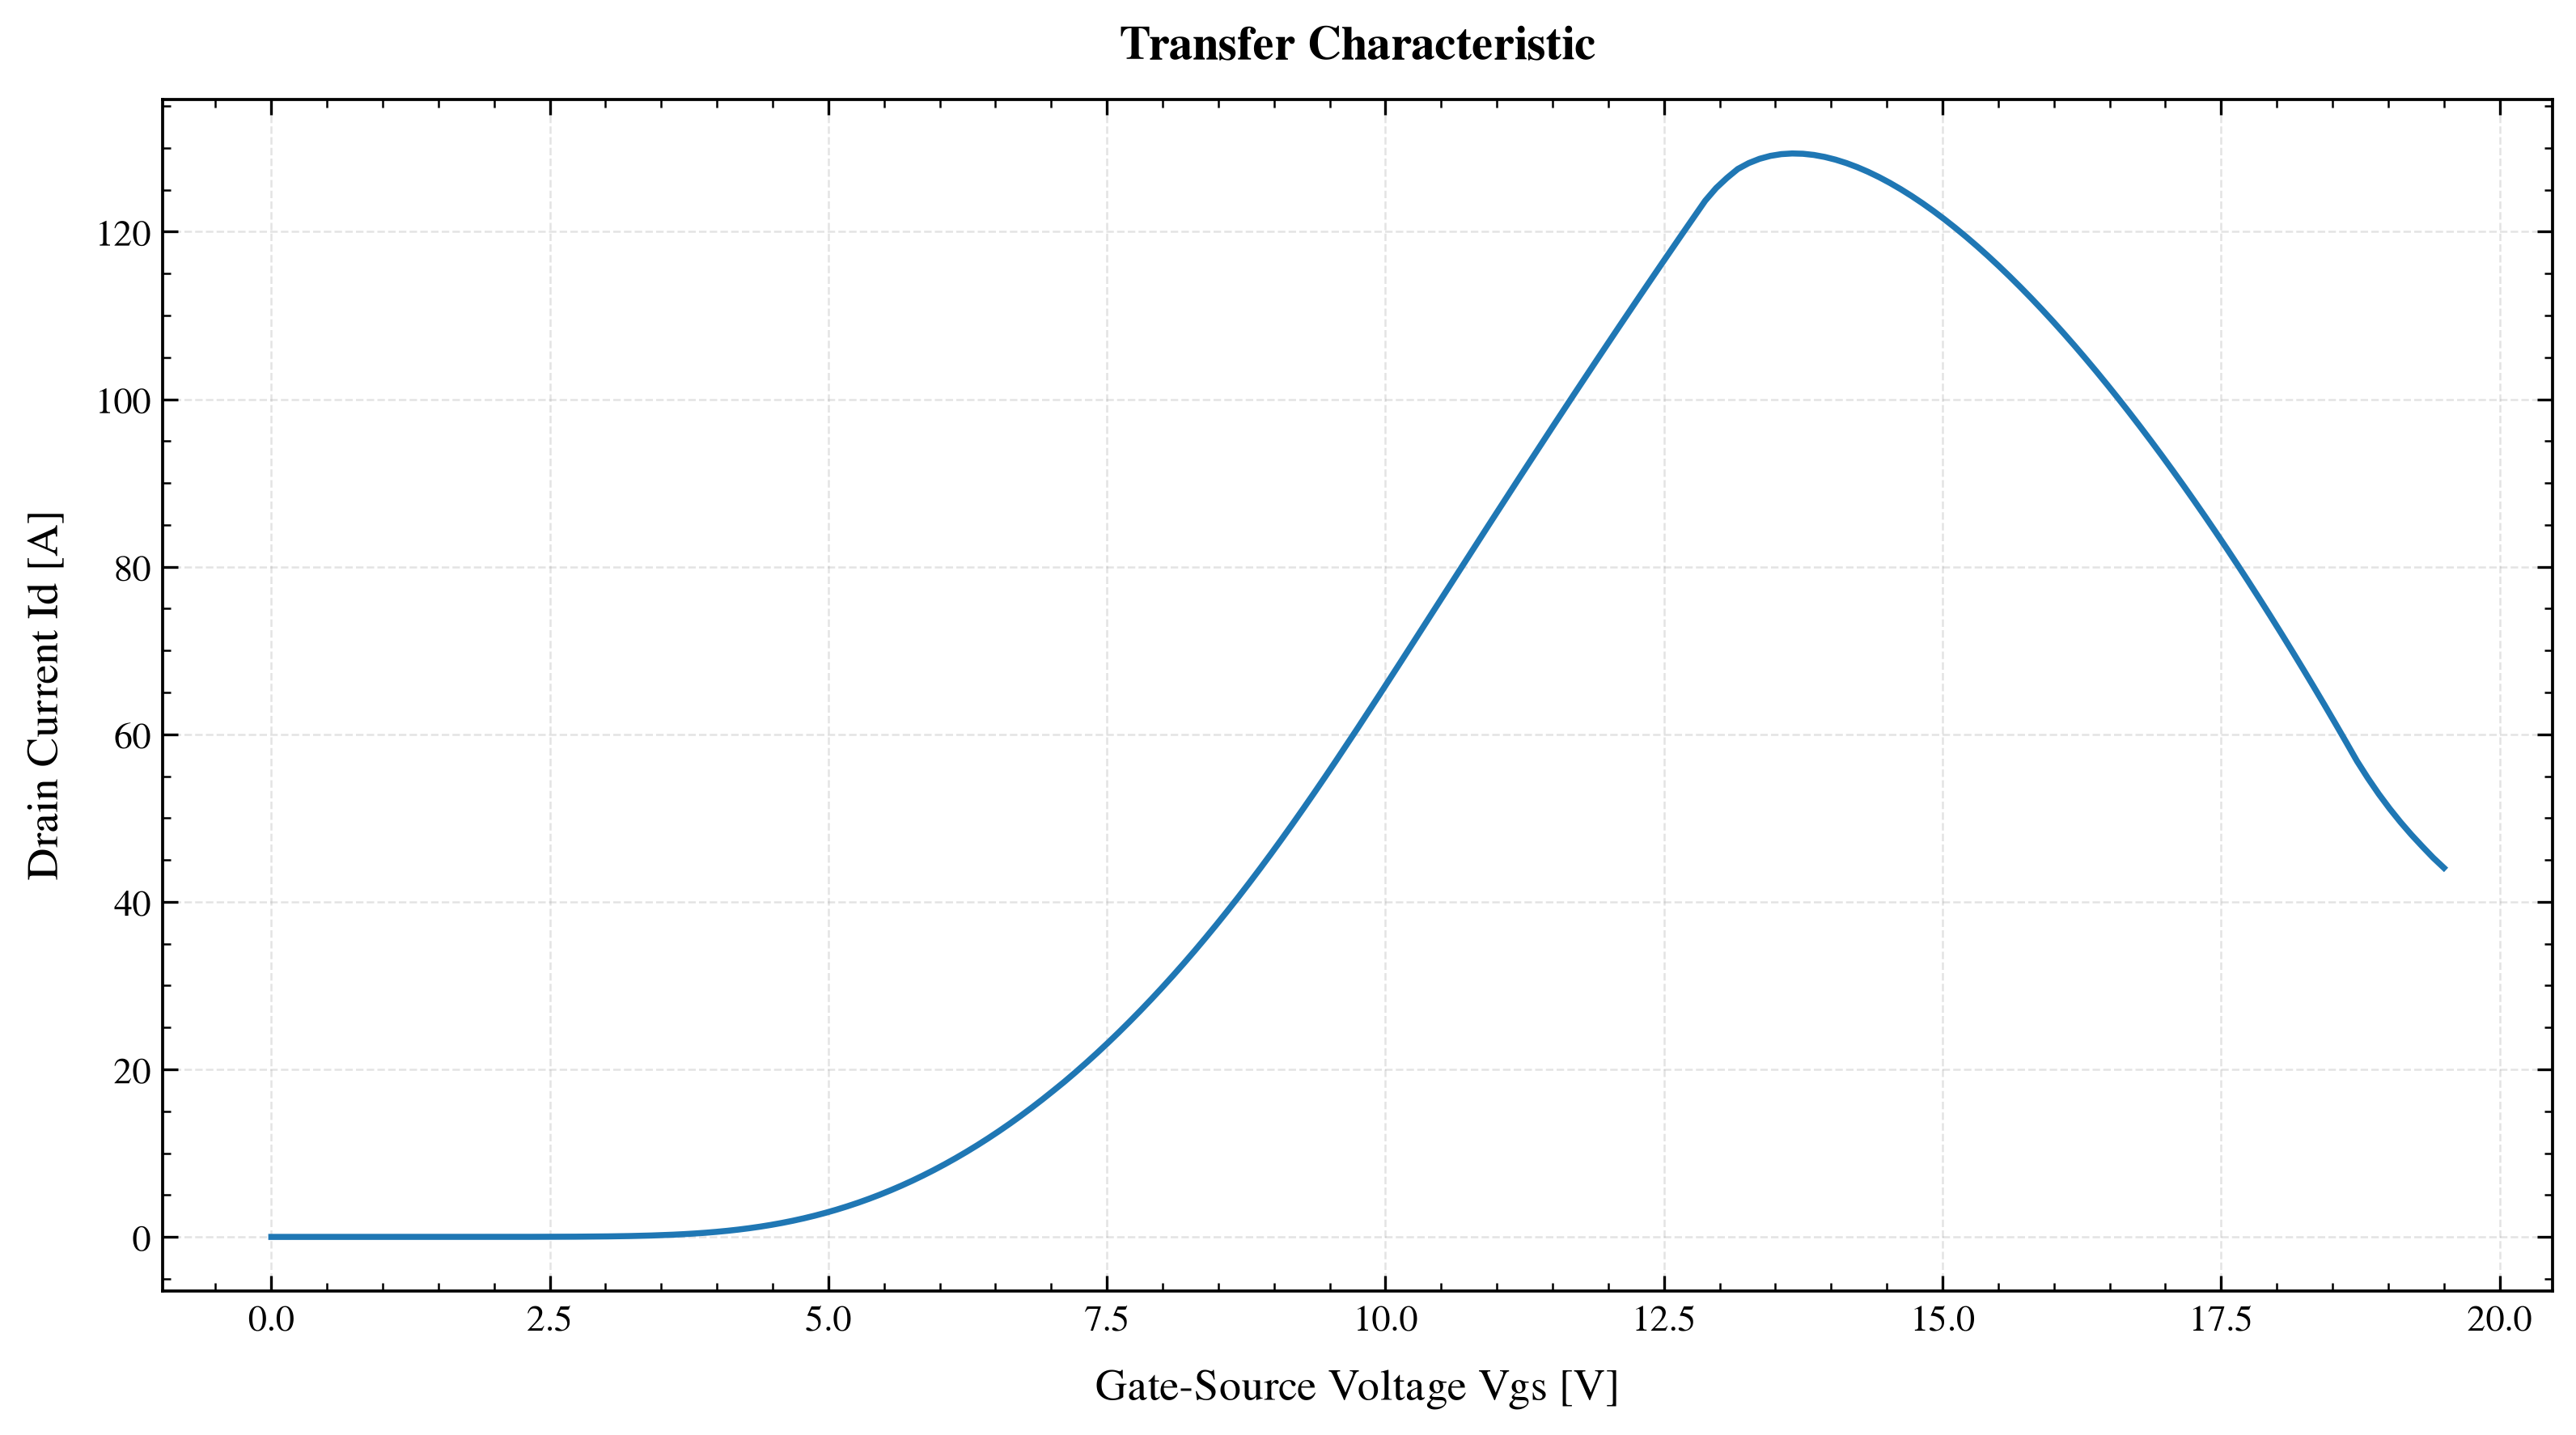

gfs @ plateau : 7.87 S
Vplateau     : 6.219 V


In [61]:
data2 = plot_curve(
    "curve2_transfer_characteristic", "curve_vgs", "curve_id",
    title="Transfer Characteristic",
    xlabel="Gate-Source Voltage Vgs [V]",
    ylabel="Drain Current Id [A]")
print(f"gfs @ plateau : {data2['extracted']['gfs_s']:.2f} S")
print(f"Vplateau     : {data2['extracted']['v_plateau_v']:.3f} V")

---
## Curve 3 — On-State Resistance
Rds(on) = Vds/Id in the ohmic region at the primary gate drive.

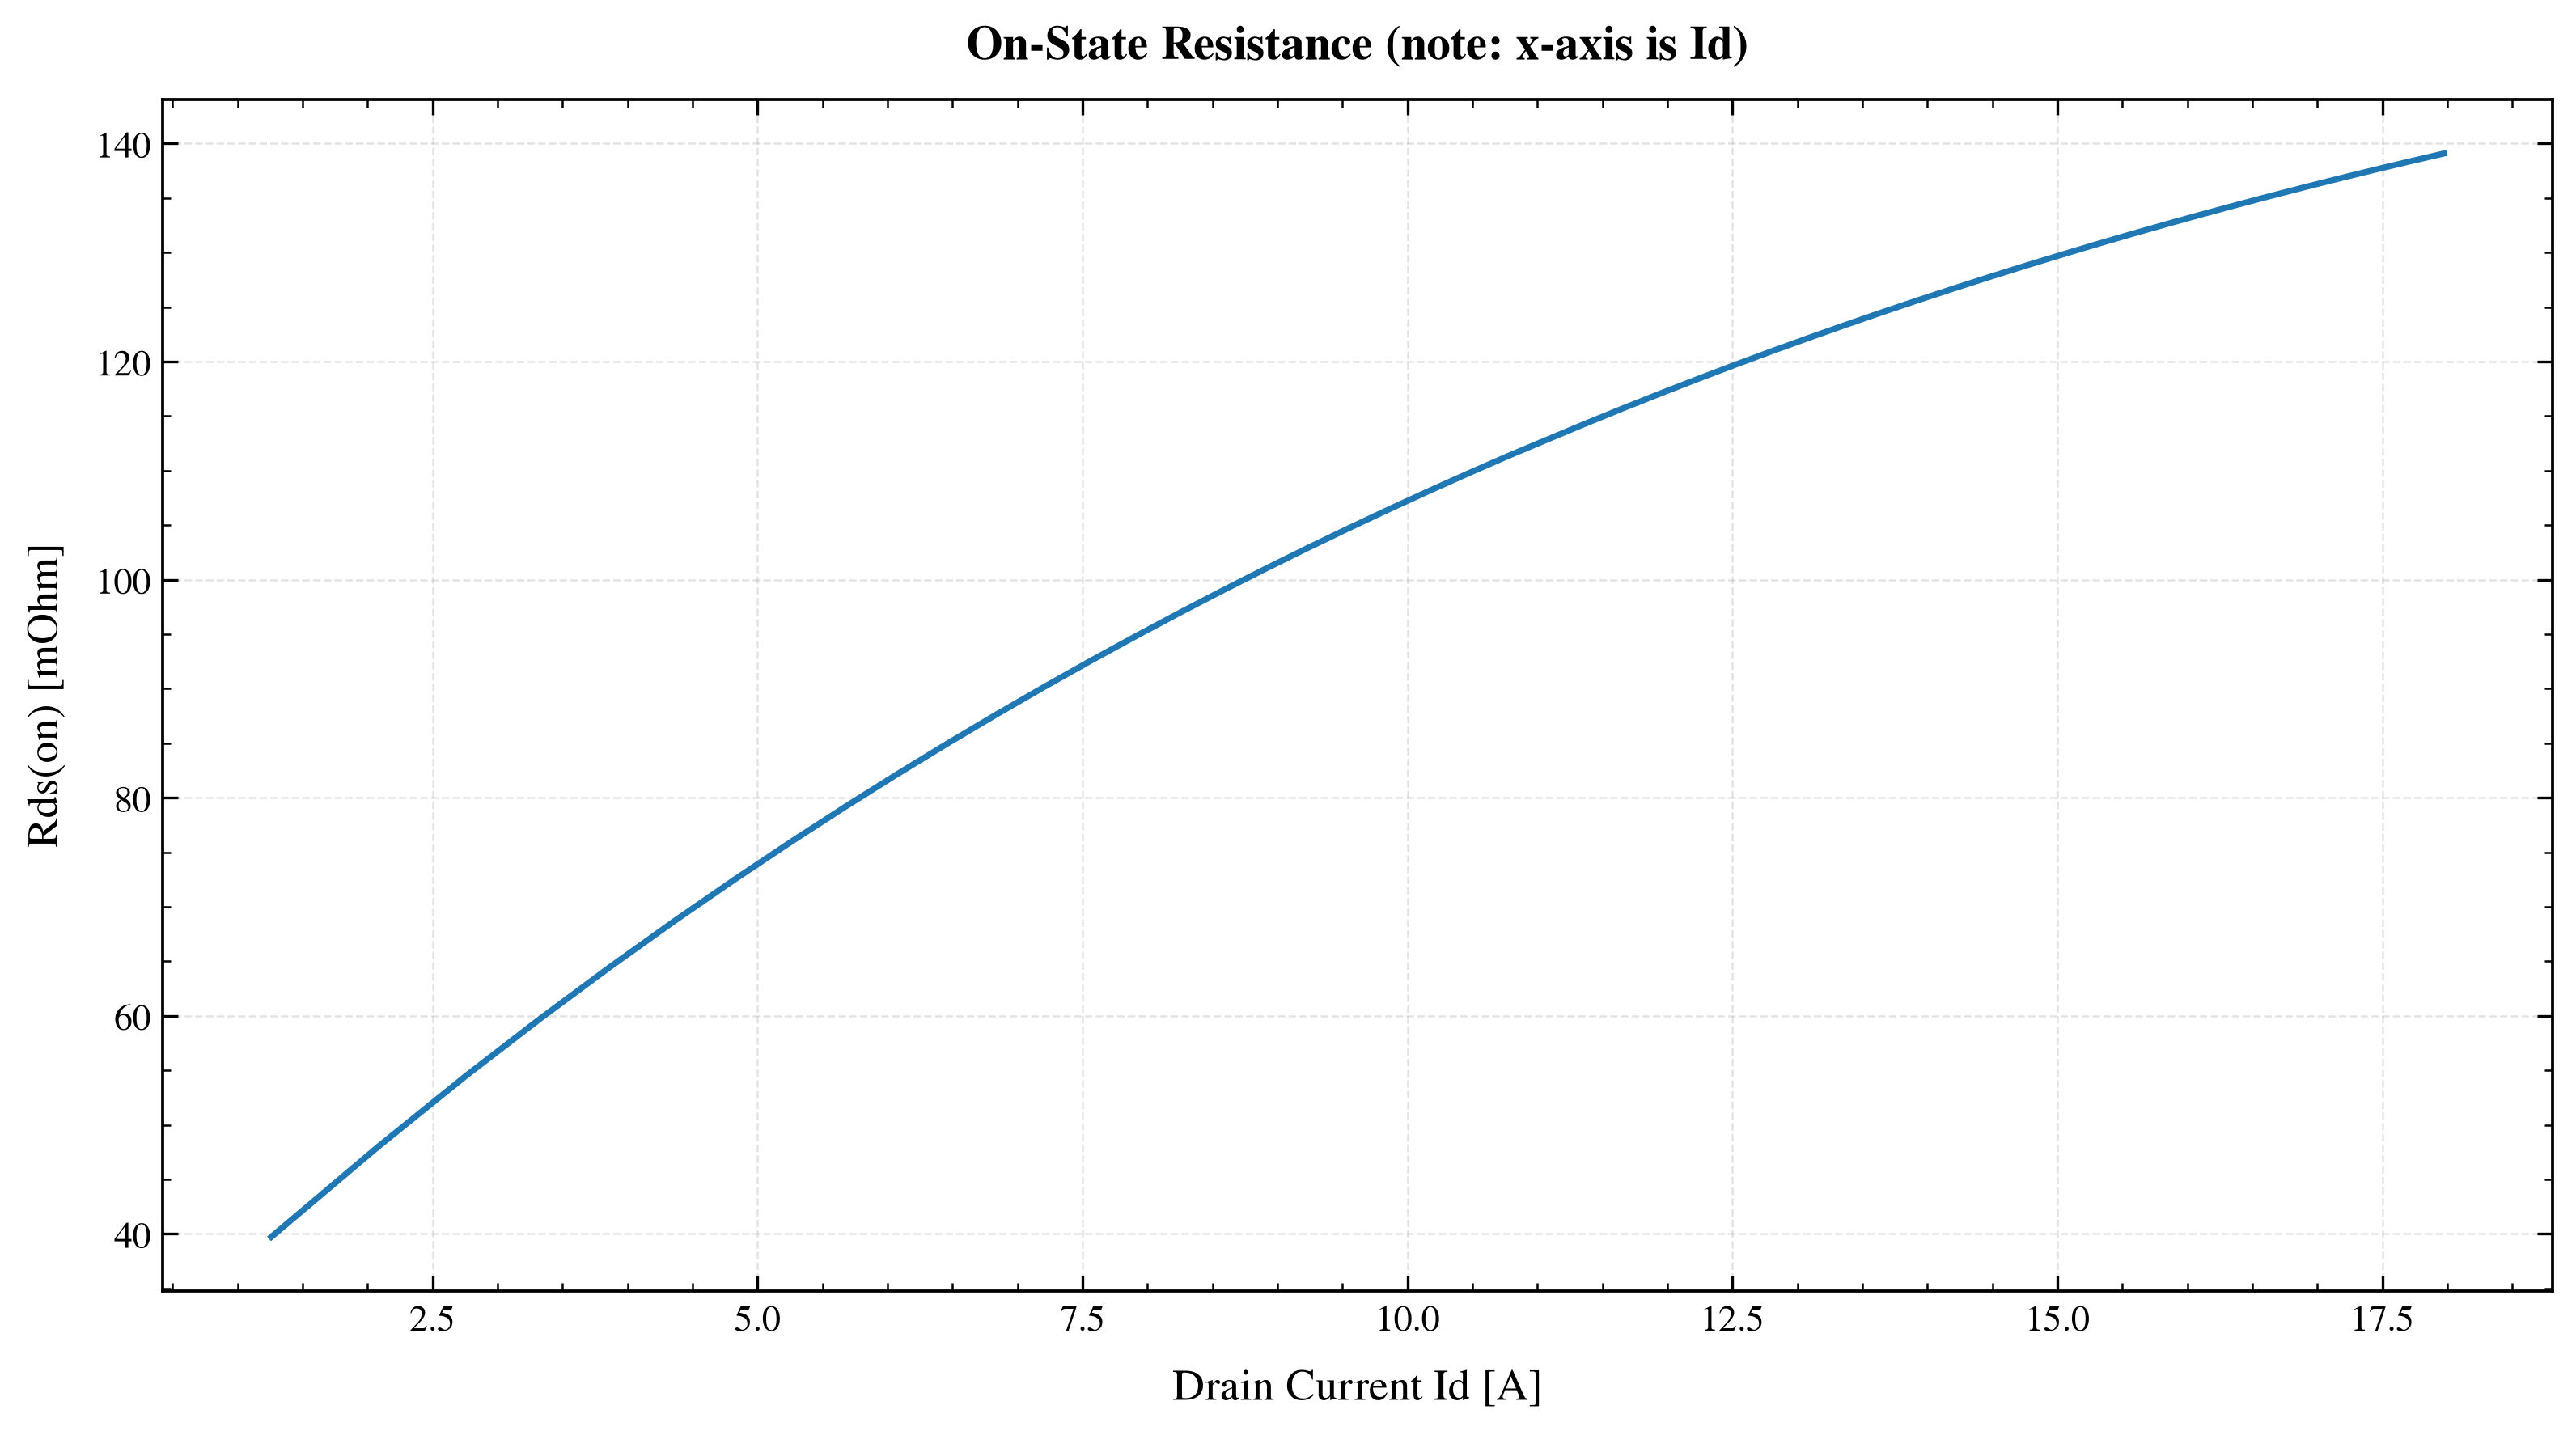

In [62]:
data3 = plot_curve(
    "curve3_rds_on", "curve_id", "curve_rds_mohm",
    title="On-State Resistance (note: x-axis is Id)",
    xlabel="Drain Current Id [A]",
    ylabel="Rds(on) [mOhm]")

---
## Curve 4 — Capacitances
Ciss / Coss / Crss vs Vds via small-signal AC probes.

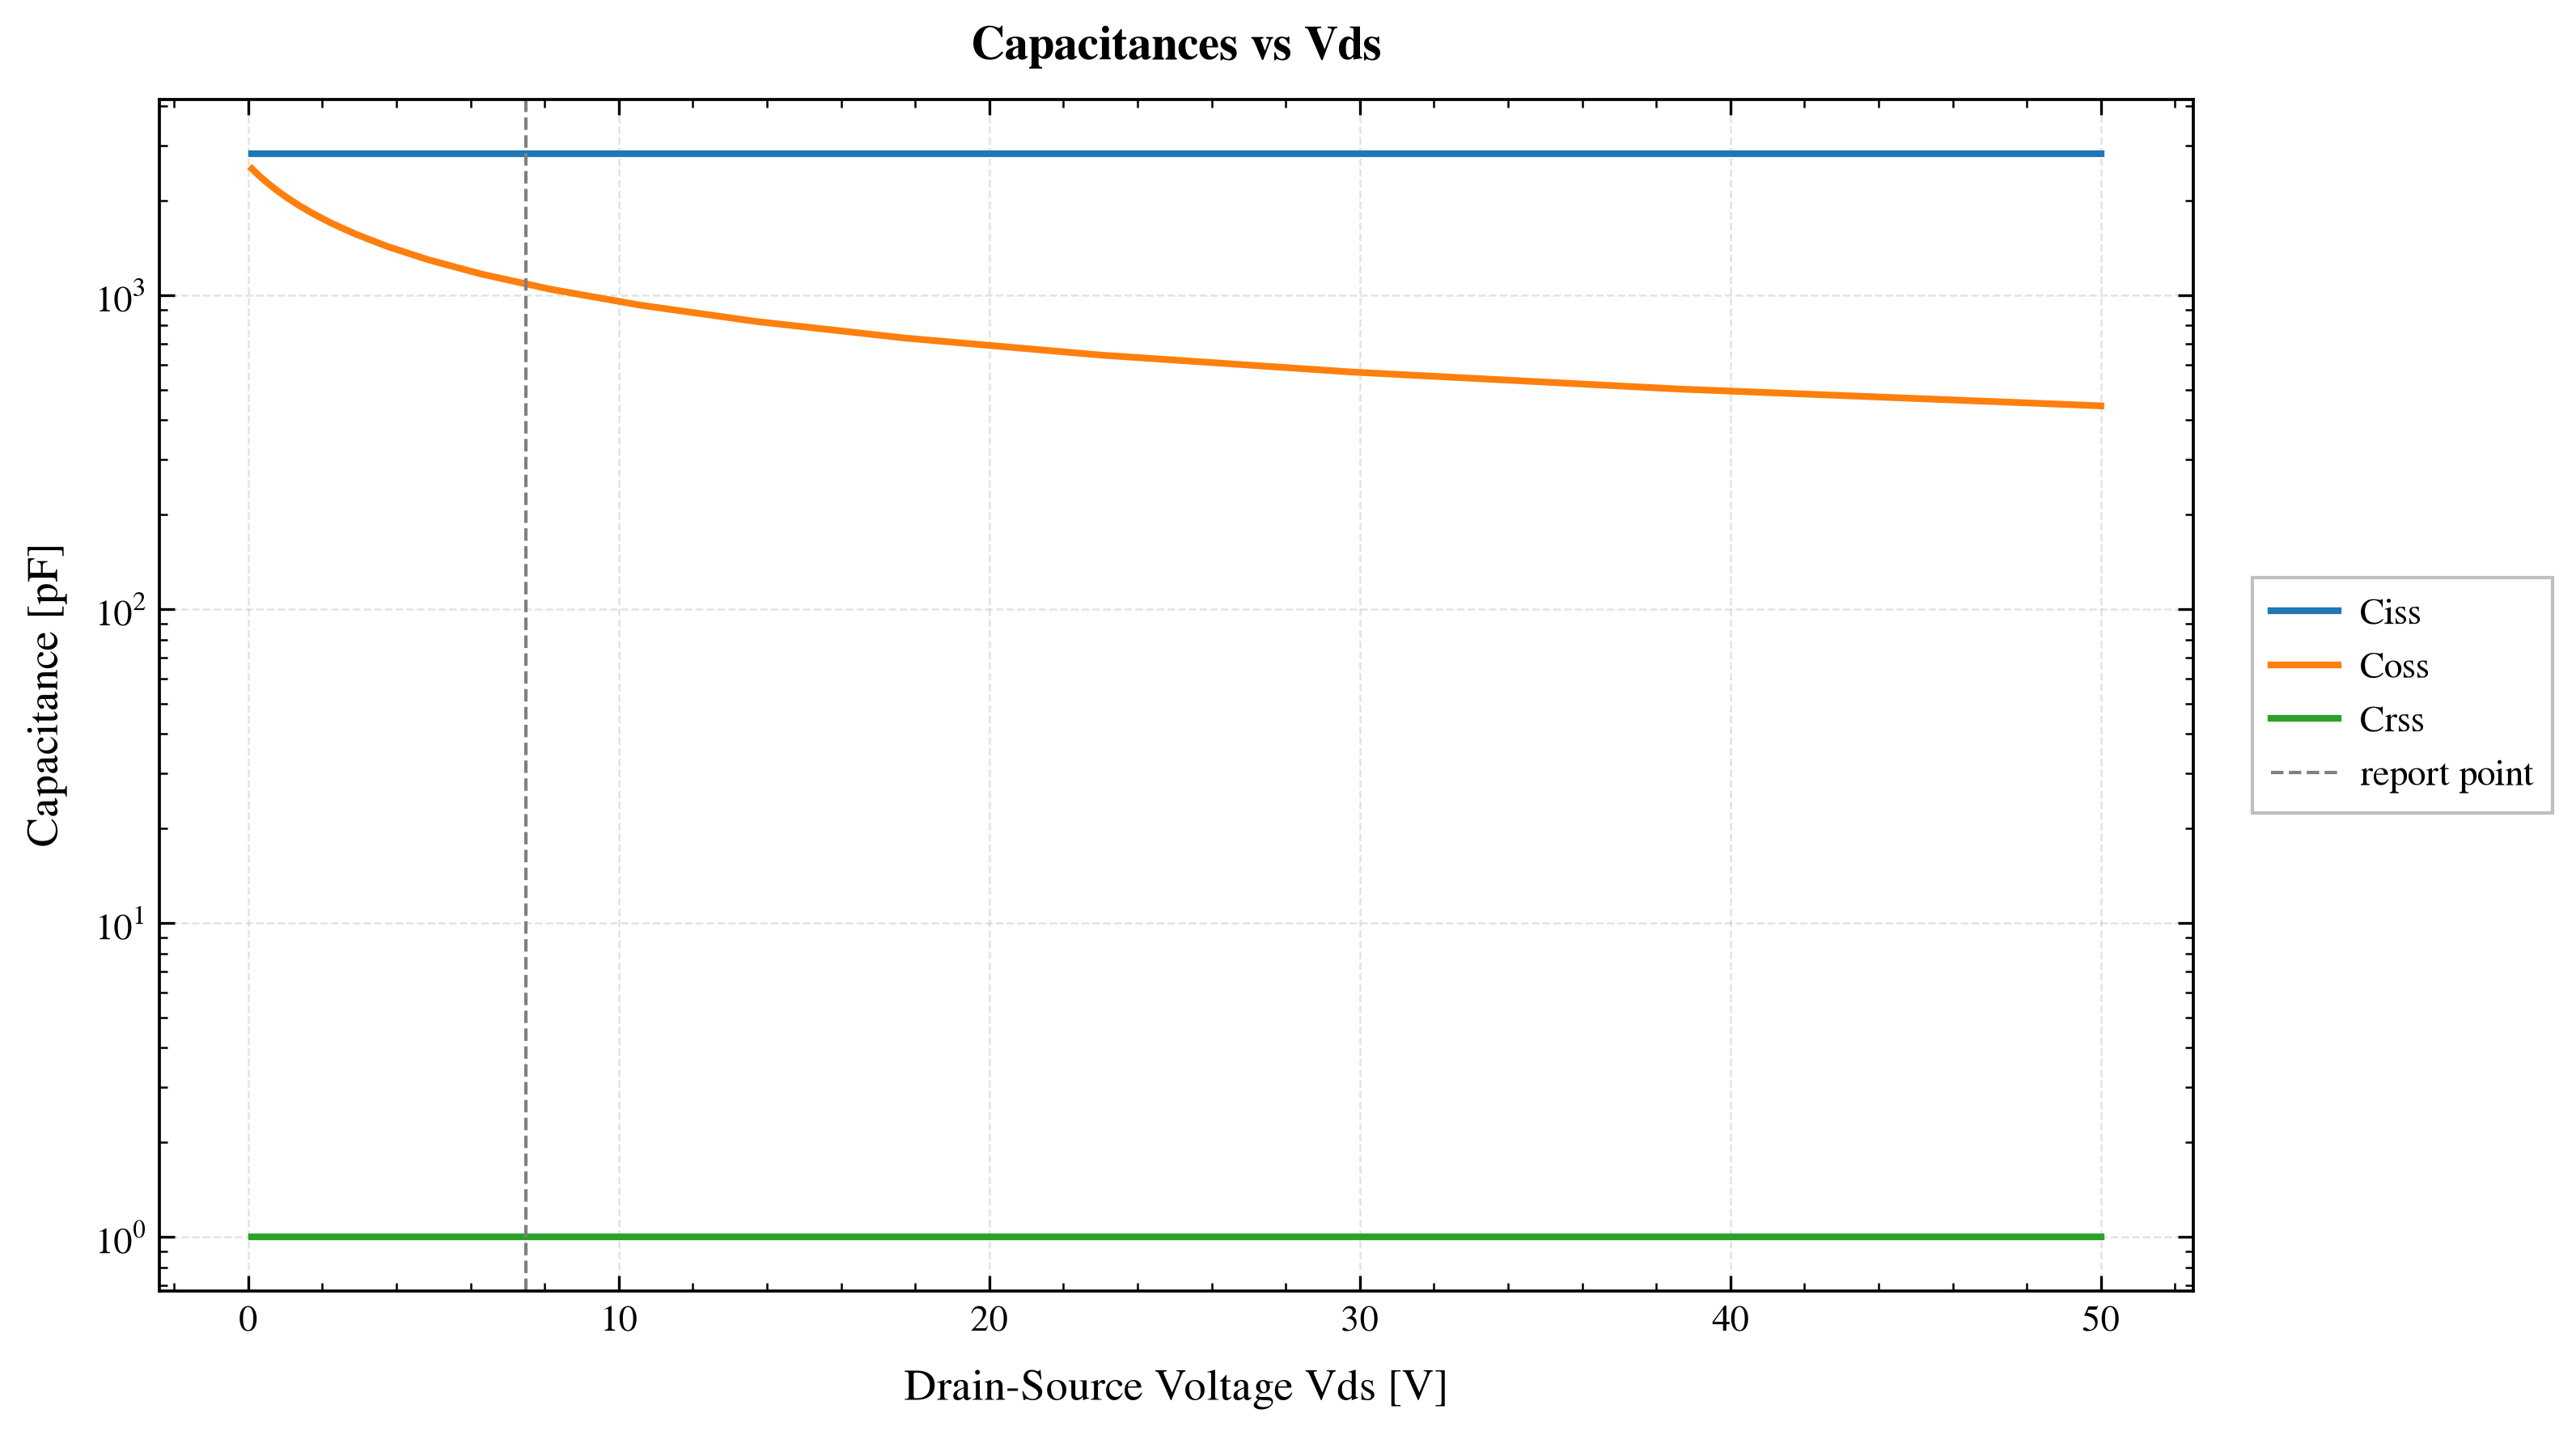

Ciss @ ref : 2825.8 pF
Coss @ ref : 1087.2 pF
Crss @ ref : 1.0 pF


In [63]:
c4 = load_output(VENDOR, "curve4_capacitances")
cap_data = {
    "Ciss": ("curve4_ciss", None),
}
# re-read full curves from the testbench outputs saved by pipeline
# (pipeline stores scalar refs; re-run bench curves quickly from YAML notes)
from simulation.testbenches.capacitance import CapacitanceTestbench
from parser.netlist import resolve_pin_connections
lib = Path(cfg["library"]); subckt = cfg["subcircuit"]
roles = resolve_pin_connections(lib, subckt,
    pin_order_semantic=cfg.get("pins", {}).get("pin_order_semantic"))
cond = cfg["conditions"]
ciss, coss, crss = CapacitanceTestbench(f_meas=cond.get("F_meas")).run(
    lib, subckt, vds_min=cond["Vds_cap_min"], vds_max=cond["Vds_cap_max"],
    points=cond["Cap_points"], pin_roles=roles)

fig, ax = plt.subplots(figsize=(10.5, 5.8), layout="constrained")
for curve, label, color in ((ciss, "Ciss", "tab:blue"),
                            (coss, "Coss", "tab:orange"),
                            (crss, "Crss", "tab:green")):
    ax.semilogy(curve.x_data, np.array(curve.y_data)*1e12, label=label,
                color=color, lw=2)
ax.axvline(cond.get("Cap_ref_Vds", cond["Vds_cap_max"]*0.25), ls="--",
           color="gray", lw=1, label="report point")
ax.set_xlabel("Drain-Source Voltage Vds [V]")
ax.set_ylabel("Capacitance [pF]")
ax.set_title("Capacitances vs Vds")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()
ex4 = c4["extracted"]
print(f"Ciss @ ref : {ex4['ciss_f']*1e12:.1f} pF")
print(f"Coss @ ref : {ex4['coss_f']*1e12:.1f} pF")
print(f"Crss @ ref : {ex4['crss_f']*1e12:.1f} pF")

---
## Curve 5 — Gate Charge (Quasi-Static)
Qg(Vgs) three-segment reconstruction with Miller plateau markers.

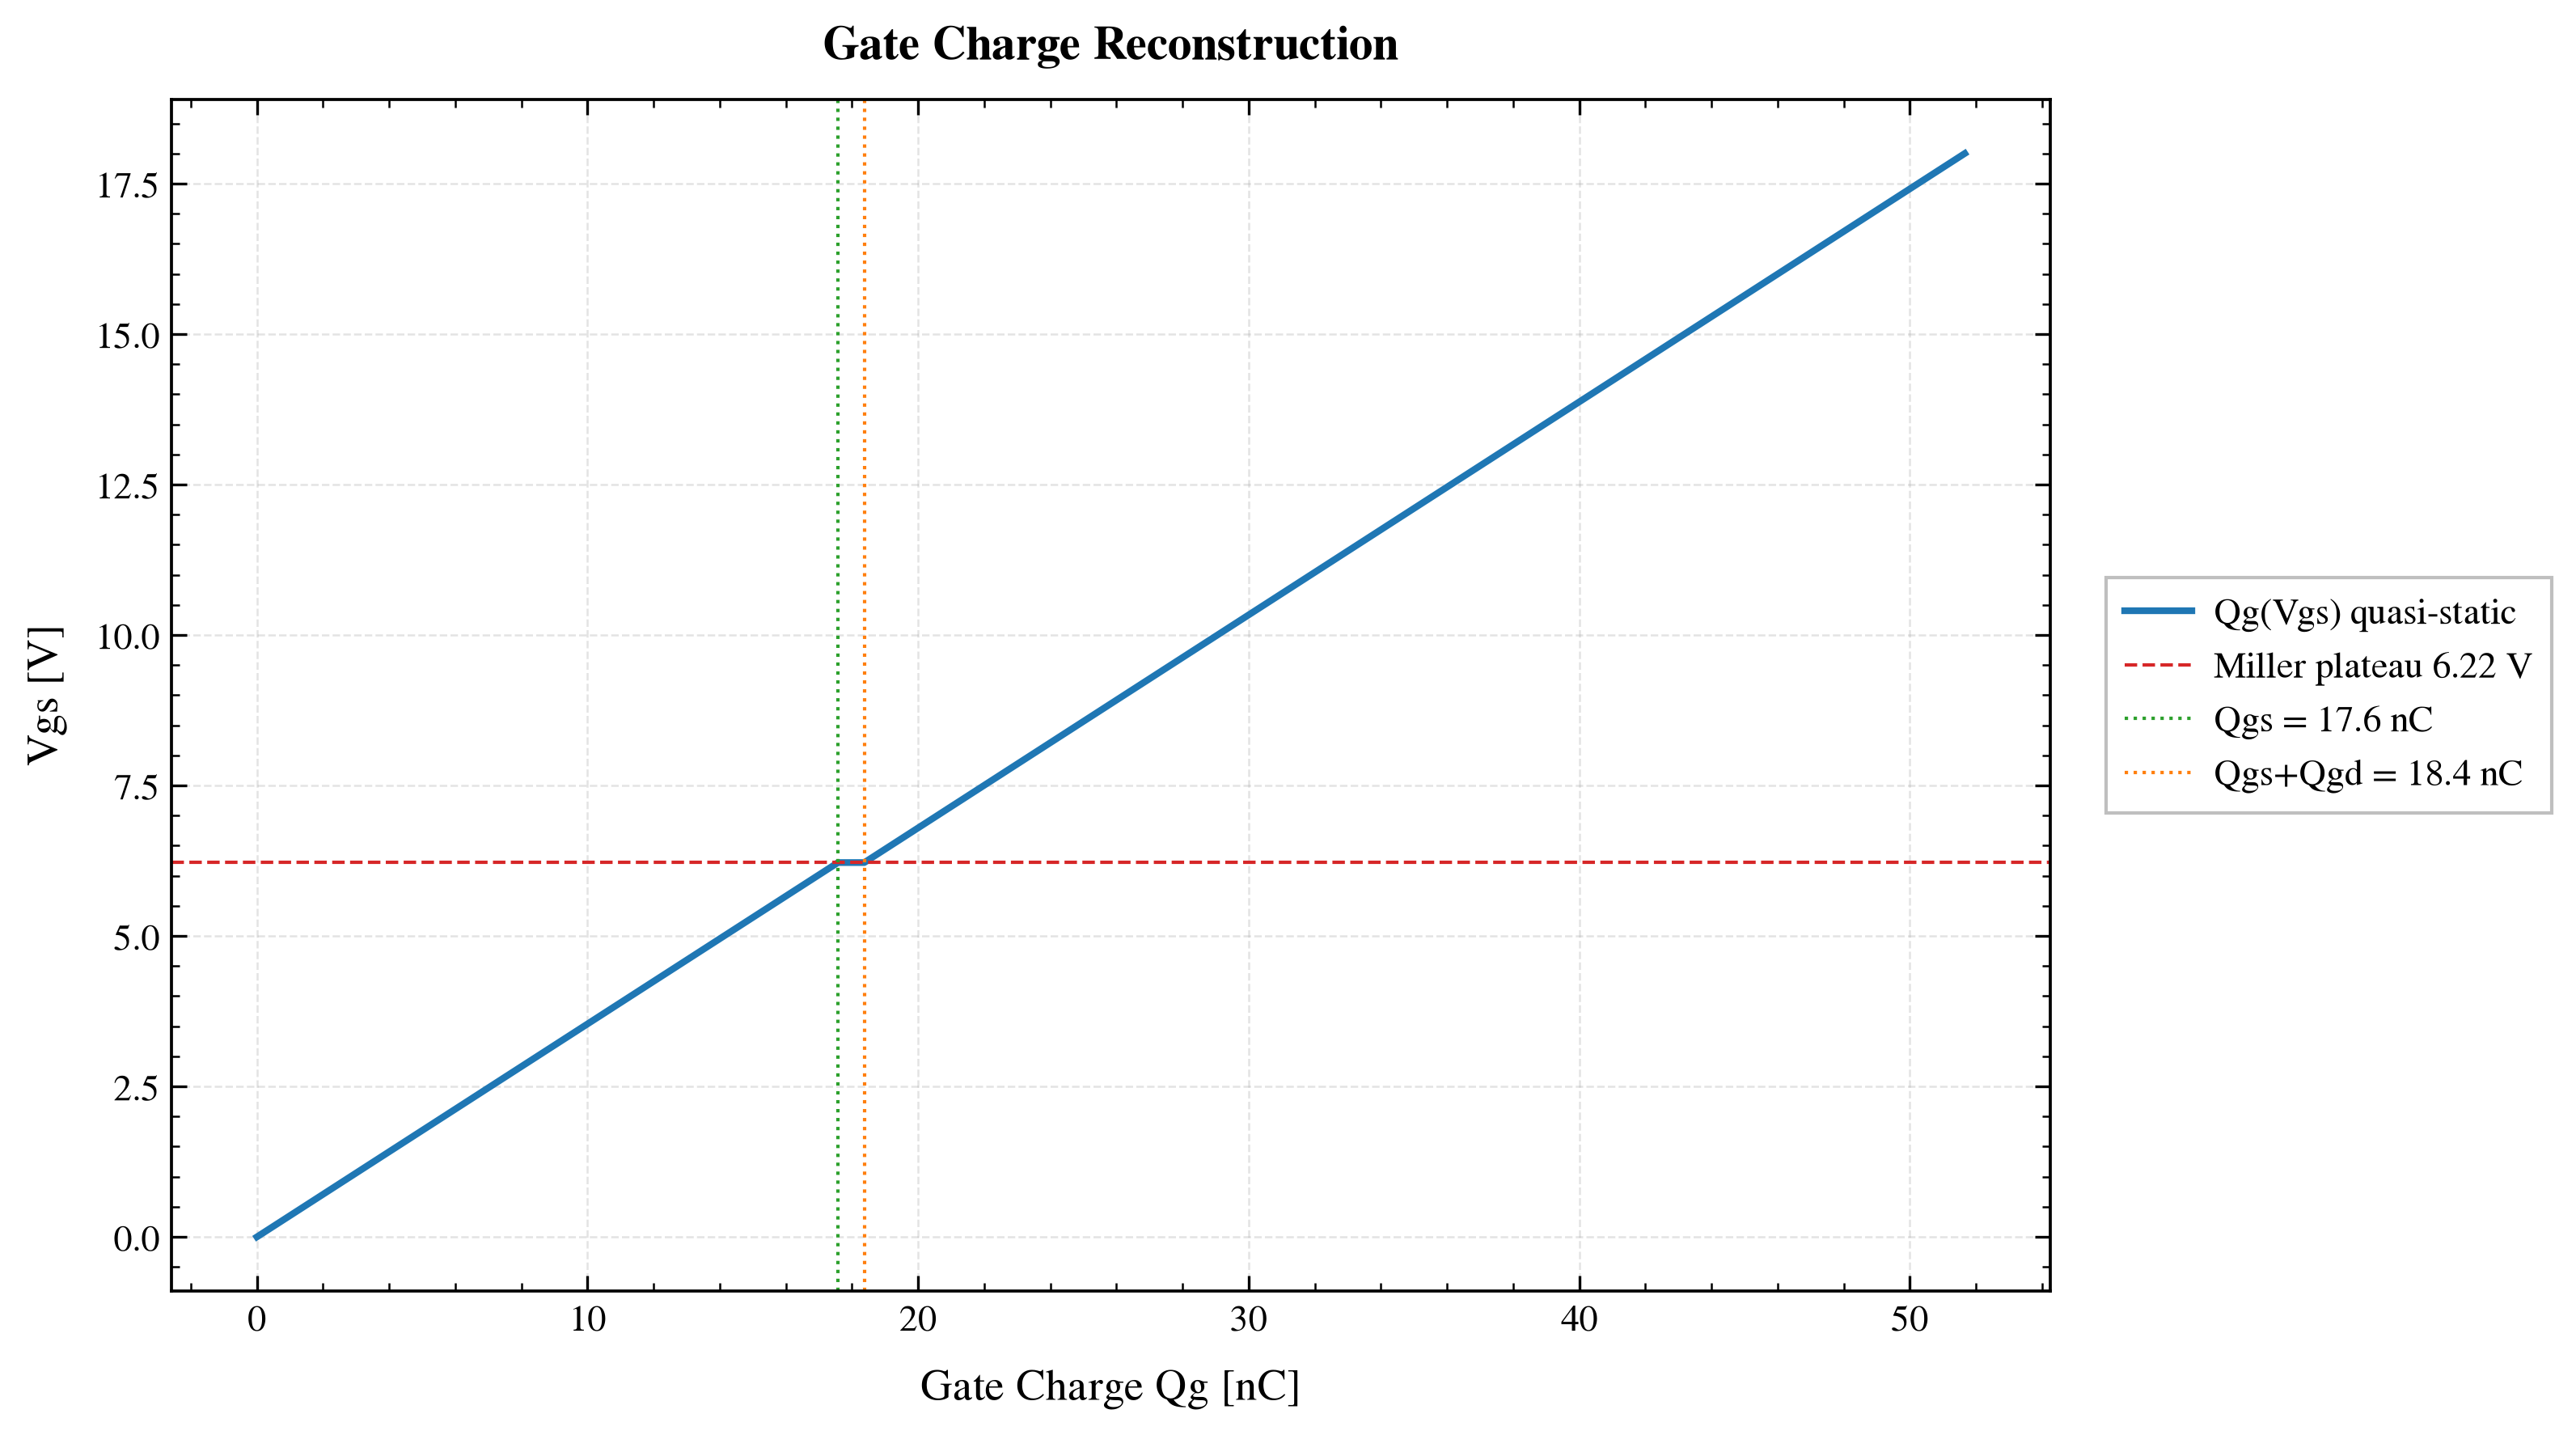

v_plateau_v : 6.22
qgs_nc      : 17.57
qgd_nc      : 0.80
q_tail_nc   : 33.29
qg_total_nc : 51.66


In [64]:
import numpy as np
d5 = load_output(VENDOR, "curve5_gate_charge")
ex5 = d5["extracted"]
qg = np.array(ex5["curve_qg_nc"]); vgs = np.array(ex5["curve_vgs"])
fig, ax = plt.subplots(figsize=(10.5, 5.8), layout="constrained")
ax.plot(qg, vgs, lw=2, label="Qg(Vgs) quasi-static")
vp = ex5["v_plateau_v"]
ax.axhline(vp, ls="--", color="tab:red", lw=1,
           label=f"Miller plateau {vp:.2f} V")
q1 = ex5["qgs_nc"]; q2 = q1 + ex5["qgd_nc"]
ax.axvline(q1, ls=":", color="tab:green", lw=1, label=f"Qgs = {q1:.1f} nC")
ax.axvline(q2, ls=":", color="tab:orange", lw=1, label=f"Qgs+Qgd = {q2:.1f} nC")
ax.set_xlabel("Gate Charge Qg [nC]"); ax.set_ylabel("Vgs [V]")
ax.set_title("Gate Charge Reconstruction")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()
for k in ("v_plateau_v", "qgs_nc", "qgd_nc", "q_tail_nc", "qg_total_nc"):
    print(f"{k:12s}: {ex5[k]:.2f}")

---
## Curve 6 — Body Diode / Reverse Conduction
Isd vs Vsd with gate off.

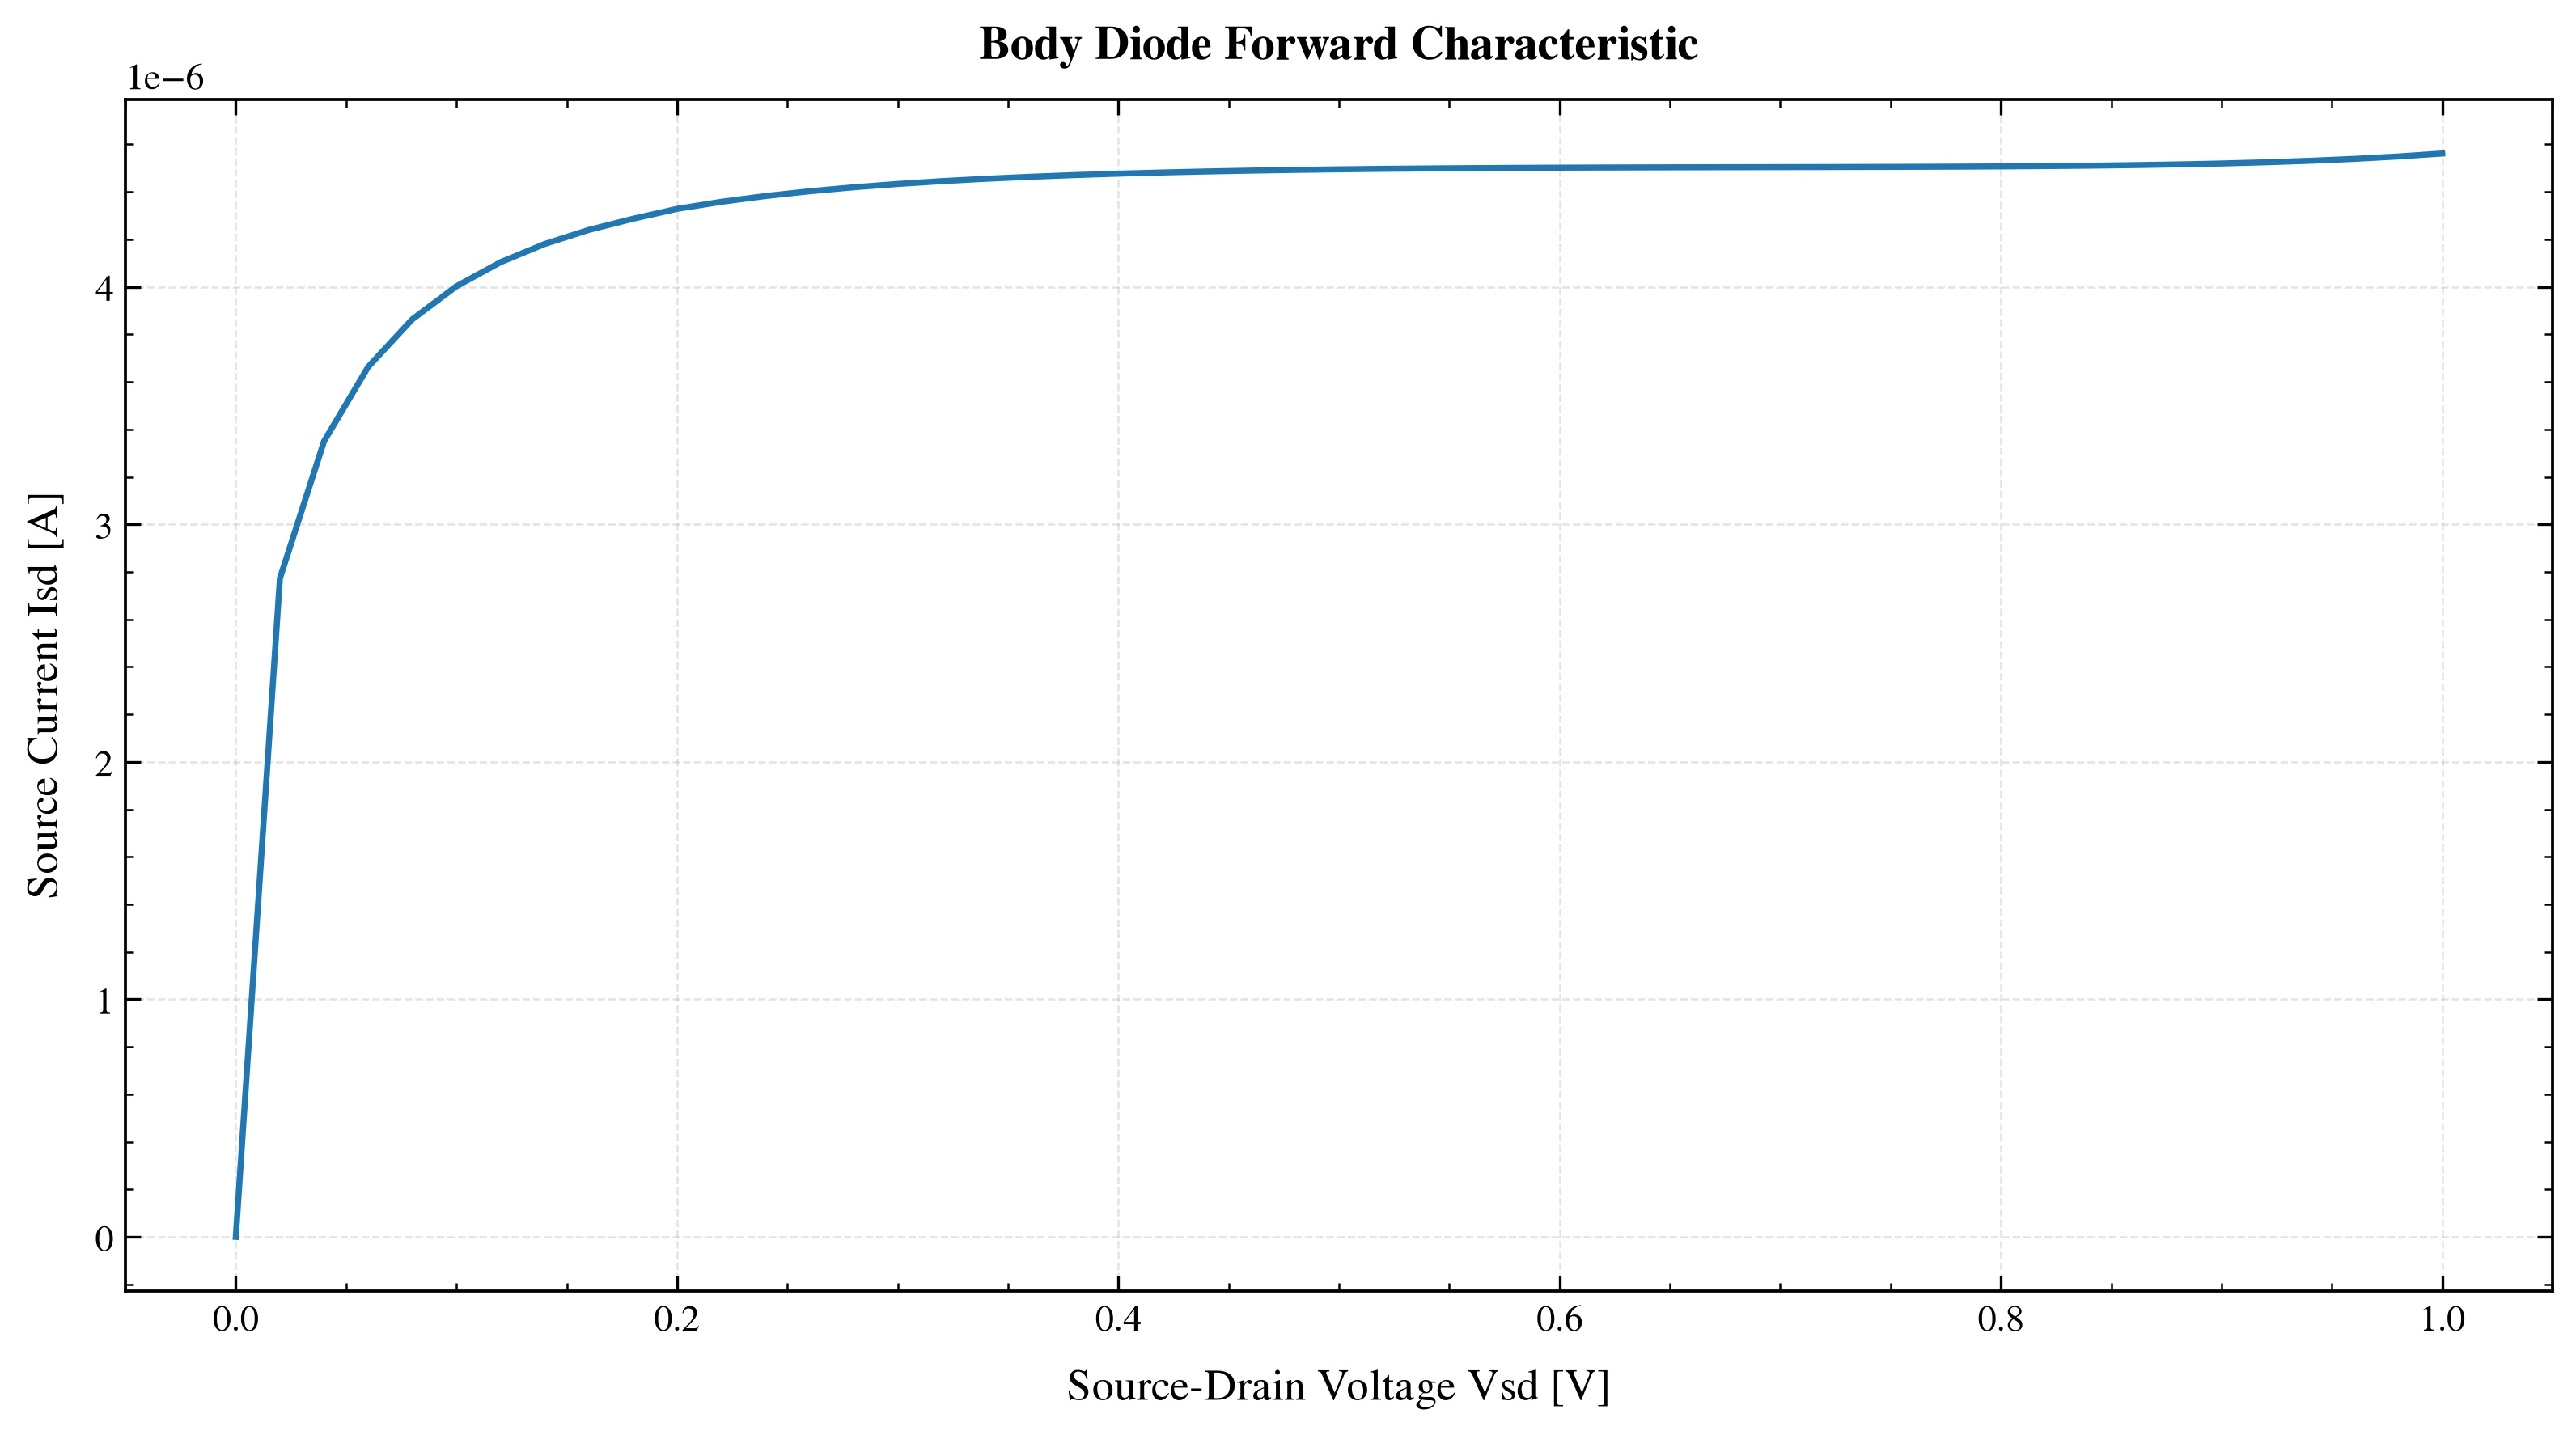

In [65]:
d6 = plot_curve(
    "curve6_body_diode", "curve_vsd", "curve_isd",
    title="Body Diode Forward Characteristic",
    xlabel="Source-Drain Voltage Vsd [V]",
    ylabel="Source Current Isd [A]")

---
## Curve 7 — Threshold Voltage
JEDEC constant-current method at the vendor's Id_th_target.

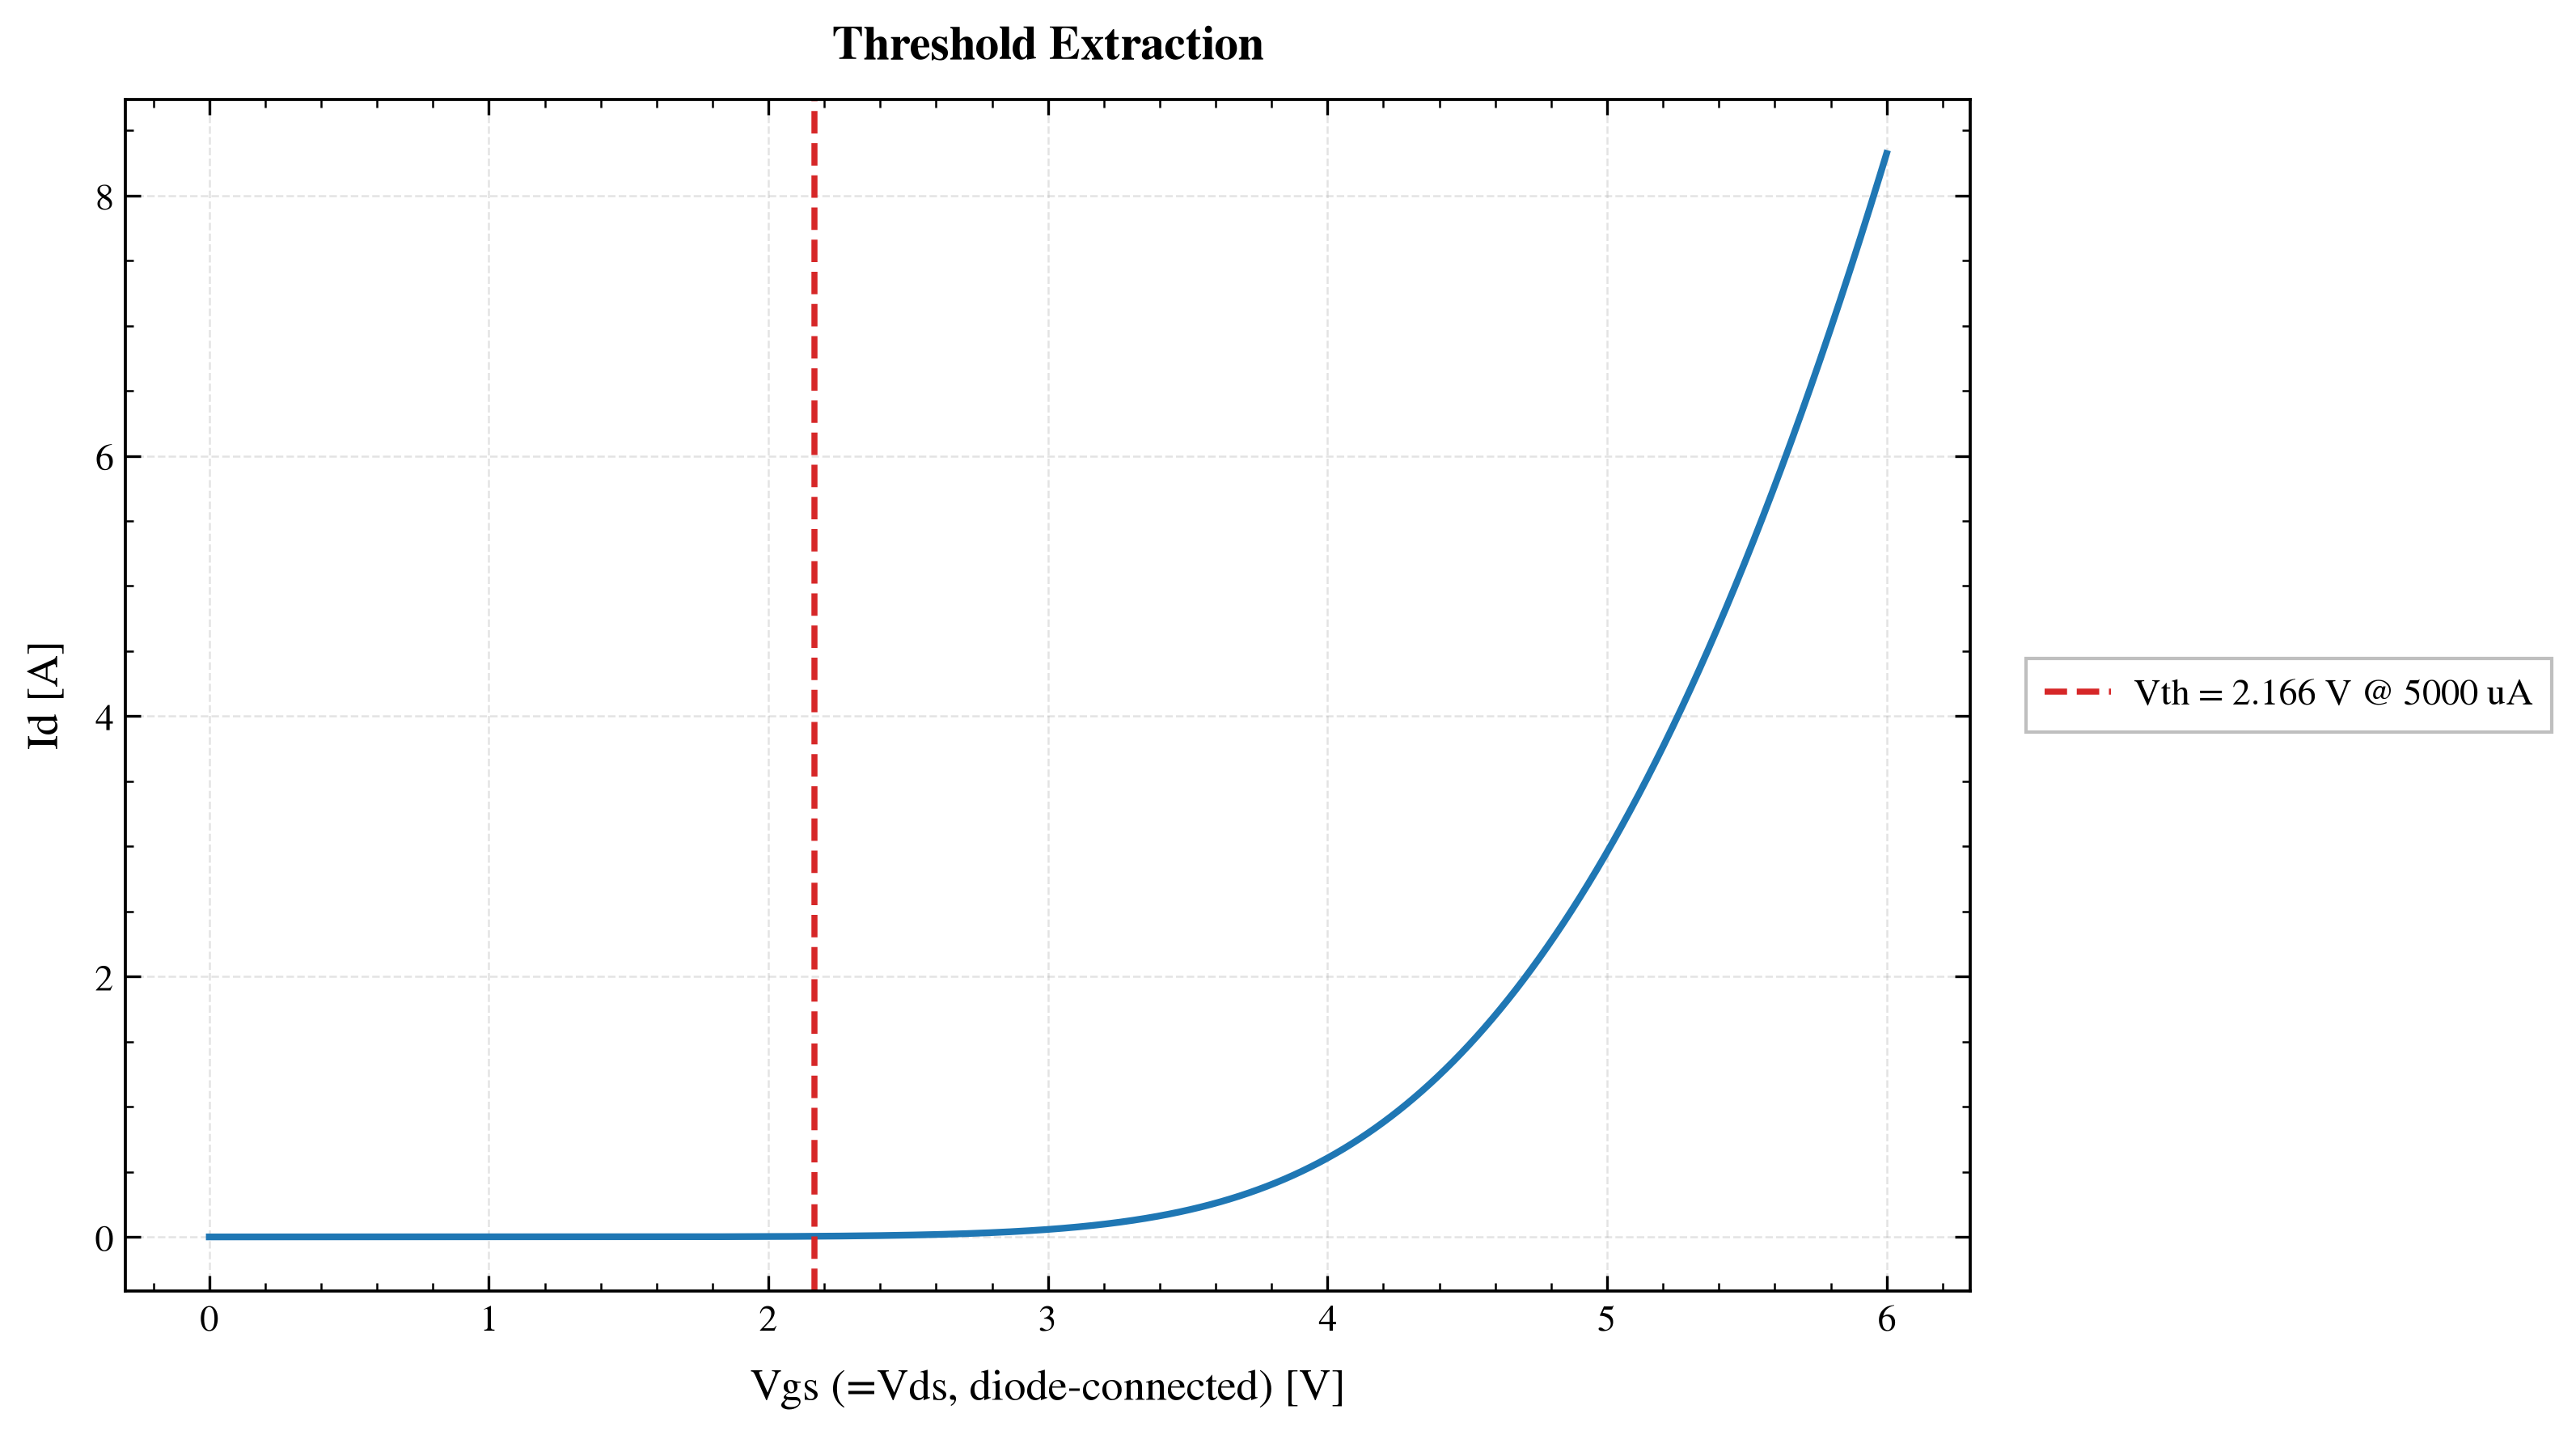

Vgs(th): 2.166 V @ Id_target=5000 uA


In [66]:
d7 = load_output(VENDOR, "curve7_threshold_voltage")
ex7 = d7["extracted"]
fig, ax = plt.subplots(figsize=(10.5, 5.8), layout="constrained")
ax.plot(ex7["curve_vgs"], ex7["curve_id"], lw=2)
vth = ex7["vth_v"]
ax.axvline(vth, ls="--", color="tab:red",
           label=f"Vth = {vth:.3f} V @ {ex7['Id_th_target']*1e6:.0f} uA")
ax.set_xlabel("Vgs (=Vds, diode-connected) [V]")
ax.set_ylabel("Id [A]")
ax.set_title("Threshold Extraction")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()
print(f"Vgs(th): {vth:.3f} V @ Id_target={ex7['Id_th_target']*1e6:.0f} uA")